# Camera Trajectory Animation Using Lie-Group Interpolation on SE(3)

**CSE5280 — Florida Institute of Technology**

---

## Table of Contents

### Part 1 — Ray Tracer Foundation
1. [Imports & Dependencies](#1-imports)
2. [Ray Class & Ray Equation](#2-ray)
3. [Sphere Class & Ray–Sphere Intersection](#3-sphere)
4. [Plane Class & Ray–Plane Intersection](#4-plane)
5. [Camera Class & Multi-Viewpoint Rendering](#5-camera)
6. [Scene Class, Shading & Recursive Ray Tracing](#6-scene)
7. [Static Viewpoint Renders](#7-static)

### Part 2 — SE(3) Lie-Group Camera Animation
8. [SE(3) Math: Exp/Log Maps & Geodesic Interpolation](#8-se3-math)
9. [Keyframe Poses & Interpolated Trajectory](#9-keyframes)
10. [Render Animation Frames & Export GIF](#10-render)
11. [Trajectory Visualization & Lie-group vs Euclidean Comparison](#11-viz)
12. [Export MP4 Video](#12-mp4)
13. [Report](#13-report)

### Bonus Experiments
14. [Bonus A — SO(3)-only vs Full SE(3) Interpolation](#14-so3-vs-se3)
15. [Bonus B — Tangent-Space Twist Perturbations](#15-twist)
16. [Bonus C — Left vs Right Perturbations](#16-left-right)
17. [Bonus D — 8-Keyframe Closed-Loop Trajectory](#17-8kf)

---


---
# Part 1 — Ray Tracer Foundation


## 1. Imports & Dependencies <a id='1-imports'></a>


In [12]:
__author__ = 'eribeiro'
#
import numpy as np               # Numpy library
from PIL import Image as im      # Basic image processing library
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import cv2                        # For MP4 video export
import os, time  # Basic image processing library

!pip -q install https://github.com/tussedrotten/pylie/archive/master.zip
!pip -q install https://github.com/tussedrotten/visgeom/archive/master.zip


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Ray Class & Ray Equation <a id='2-ray'></a>


### Line (ray) equation

The ray equation is given by:

$$
\begin{align}
    {\bf p}\left(t\right) = {\bf e} + {\bf d} t,
\end{align}
$$
where:
$$
\begin{align}
    {\bf d}  = {\bf s} - {\bf e}.
\end{align}
$$


![](https://github.com/eraldoribeiro/raycasting/blob/main/ray.jpg?raw=1)

The diagram shows the main components of the 3-D scene (and virtual camera), i.e.:

- ${\bf e} \in \mathbb{R}^3$ is the eye location (i.e., viewer)

- ${\bf s} \in \mathbb{R}^3$ is a point on the image plane

- ${\bf d} \in \mathbb{R}^3$ is the ray direction

- $f \in \mathbb{R}$ is the focal distance (i.e., perpendicular distance between the center of projection and the image plane.




In [13]:
class Ray:
    """A class representing a ray (line in space).

    Uses the parametric representation of a line, p(t) = e + (s - e)*t.

    The ray passes through the following two points:

    e = [e_u, e_v, e_w] representing the eye location in 3-D, and
    s = [e_u, e_v, e_w] representing a point on the image plane.

    Attributes:
        e: 3x1 np.array, e.g.,
        s: 3x1 np.array
    """

    def __init__(self, e, s):
        """Constructor method

        Args:
            e (3x1 np.array): Eye location
            s (3x1 np.array): Point on the image plane
        """
        self.e = e
        self.s = s


    def get3DPoint(self, t):
        """Calculates the location of a 3-D point along the ray given t.

        Args:
            t (float): Parameter of the ray equation
        Returns:
            p (3x1 nd.array): Point p(t) = e + (s - e) * t.
        """
        p = self.e + (self.s - self.e) * t    # p(t) = e + (s - e) * t

        return p


    


## 3. Sphere Class & Ray–Sphere Intersection <a id='3-sphere'></a>


### Sphere equation

The sphere equation in vector form is given by:

$$
\begin{align}
    \left({\bf p} - {\bf c}\right)\cdot \left({\bf p} - {\bf c}\right) - r^2 = 0,
\end{align}
$$

where ${\bf c} \in \mathbb{R}^3$ is the center of the sphere.

#### Ray-sphere intersection
First, we substitute the ray equation into the sphere equation, i.e.:

$$
\begin{align}
    \left({\bf e} + {\bf d}\,t - {\bf c}\right)\cdot \left({\bf e} + {\bf d}\,t - {\bf c}\right) - r^2 = 0.
\end{align}
$$

Then, we expand the dot product (similarly to using the distributive property in multiplication) and re-arrange the terms to obtain:

$$
\begin{align}
    {\left({\bf d}\cdot {\bf d}\right)}t^2 + {2\,{\bf d}\cdot\left({\bf e} - {\bf c}\right)}\,t + {\left({\bf e} - {\bf c}\right) \cdot \left({\bf e} - {\bf c}\right) - r^2} = 0,
\end{align}
$$

which is the classic quadratic equation:

$$
\begin{align}
    {A}t^2 + {B}\,t + {C} = 0.
\end{align}
$$

Its solution for t is given by:

$$
\begin{align}
    t = \frac{-B\pm\sqrt{B^2-4AC}}{2A}.
\end{align}
$$







In [14]:
class Sphere:
    def __init__(self, c, r, k, reflectivity=0.0, transmission=0.0, ior=1.5, roughness=0.0):
        self.Center = c
        self.Radius = r
        self.Color = k
        self.reflectivity = reflectivity
        self.transmission = transmission 
        self.ior = ior
        self.roughness = roughness # 0.0 = mirror, > 0.0 = glossy

    def Intersect(self, ray):
        d = ray.s - ray.e
        e = ray.e
        c = self.Center
        r = self.Radius
        A = np.dot(d, d)
        B = 2.0 * np.dot(d, (e - c))
        C = np.dot((e - c), (e - c)) - r * r
        delta = B*B - 4.0 * A * C
        if delta < 0:
            return float("inf")
        t1 = (-B - np.sqrt(delta)) / (2.0 * A)
        t2 = (-B + np.sqrt(delta)) / (2.0 * A)
        t = np.min([t1, t2])
        return t if t > 0 else float("inf")

    def get_normal(self, p):
        return (p - self.Center) / np.linalg.norm(p - self.Center)

## 4. Plane Class & Ray–Plane Intersection <a id='4-plane'></a>


### Converting between image-plane coordinates and image-matrix indices

When creating the rays we need to take into account that the coordinates (i.e., indices) of the image matrix are $(i,j)$ and the coordinates of the image plane are $(u,v)$.  

We also need to remember that the origin of the $(u,v)$-system is at the center of the plane while the origin of the image matrix is (usually) at the top-left corner.

As a result, we must convert between geometric $(u,v)$ coordinates and matrix indices $(i,j)$.

![](https://github.com/eraldoribeiro/raycasting/blob/main/uv_ij.jpg?raw=1)



### The plane equation
The plane through ${\bf p}_1 = \left(u,v,w\right)^\mathsf{T}$, with surface normal ${\bf n} = \left(n_u,n_v,n_w\right)^\mathsf{T}$ is given by the following implicit equation:

$$
\begin{align}
    \left({\bf p} - {\bf p}_1\right) \cdot {\bf n} = 0.
\end{align}
$$

#### Ray-plane intersection

The equation of the ray (line) between the eye and a point on the image plane is given by:

$$
\begin{align}
    {\bf p}\left(t\right) = {\bf e} + {\bf d} t,
\end{align}
$$

where:

$$
\begin{align}
    {\bf d}  = {\bf s} - {\bf e}.
\end{align}
$$

The intersection between the ray and a plane is the point ${\bf p}\left(t\right)$ for:

$$
\begin{align}
    t = \frac{({\bf p}_1 - {\bf e}) \cdot {\bf n}}{{\bf d} \cdot {\bf n}}.
\end{align}
$$




### Calculating the (unit) normal vector of a plane

Select three non-colinear points, use these points to create two vectors on the plane, then calculate their cross product. Normalize the result to obtain the (unit) normal vector.

![](https://github.com/eraldoribeiro/raycasting/blob/main/trinormal.jpg?raw=1)

(Unit) normal vector to the plane:

$$
{\bf n} = \frac{({\bf b} - {\bf a}) \,\times ({\bf c} - {\bf a})}
{\|({\bf b} - {\bf a}) \,\times ({\bf c} - {\bf a})\|}
$$

In [15]:
class Plane:
    def __init__(self, p1, n, k, reflectivity=0.0, transmission=0.0, ior=1.0, roughness=0.0):
        self.p1 = p1
        self.n = n / np.linalg.norm(n) 
        self.Color = k
        self.reflectivity = reflectivity
        self.transmission = transmission
        self.ior = ior
        self.roughness = roughness # 0.0 = mirror, > 0.0 = glossy

    def Intersect(self, ray):
        d = ray.s - ray.e
        e = ray.e
        divide = np.dot(d.flatten(), self.n.flatten()).item()
        if abs(divide) < 1e-6: return float("inf")
        t = np.dot((self.p1.flatten() - e.flatten()), self.n.flatten()).item() / divide
        return t if t > 0 else float("inf")

    def get_normal(self, p):
        return self.n

## 5. Camera Class & Multi-Viewpoint Rendering <a id='5-camera'></a>


##  Multiple Viewpoints & Camera Basis

[cite_start]To render from different angles, the camera uses an orthonormal basis $({\bf u, v, w})$ derived from the eye position ${\bf e}$, a "lookat" point, and an "up" vector[cite: 3].

  * **${\bf w}$ (Backward):** $\frac{{\bf e} - \text{lookat}}{\|{\bf e} - \text{lookat}\|}$
  * **${\bf u}$ (Right):** $\frac{\text{up} \times {\bf w}}{\|\text{up} \times {\bf w}\|}$
  * **${\bf v}$ (Up):** ${\bf w} \times {\bf u}$

[cite_start]The switching between viewpoints is implemented by updating these vectors and re-casting the primary rays from the new eye location ${\bf e}$[cite: 3].

In [16]:
class Camera:
    nchannels = 3 

    def __init__(self, f, nrows, ncols, eye, lookat, up):
        self.f = f
        self.nrows = nrows
        self.ncols = ncols
        self.eye = eye
        self.I = np.zeros([self.nrows, self.ncols, self.nchannels])
        

        self.w = (eye - lookat) / np.linalg.norm(eye - lookat)
        
        cross_up_w = np.cross(up, self.w)
        #found weird bug when looking straight down, this fixes it
        if np.linalg.norm(cross_up_w) < 1e-7:
            cross_up_w = np.cross(np.array([1, 0, 0]), self.w)
            
        self.u = cross_up_w / np.linalg.norm(cross_up_w)
        self.v = np.cross(self.w, self.u) # v is up relative to camera

    def ij2uv(self, i, j):
        u_val = (j + 0.5) - self.ncols/2
        v_val = -(i + 0.5) + self.nrows/2
        return u_val, v_val

    def constructRayThroughPixel(self, i, j):
        u_val, v_val = self.ij2uv(i, j)
        direction = u_val * self.u + v_val * self.v - self.f * self.w
        return Ray(self.eye, self.eye + direction)

    @classmethod
    def from_pose(cls, T, f, nrows, ncols):
        """Construct camera directly from a 4x4 SE(3) pose matrix T_WC.
        
        The rotation columns of T encode the camera basis:
            T[:3, 0] = u (right), T[:3, 1] = v (up), T[:3, 2] = w (backward)
            T[:3, 3] = eye position
        This lets us plug any interpolated SE(3) pose straight in.
        """
        eye    = T[:3, 3]
        lookat = eye - T[:3, 2]   # eye - w  (one step along view direction)
        up     = T[:3, 1]
        return cls(f, nrows, ncols, eye, lookat, up)


        

## 6. Scene Class, Shading & Recursive Ray Tracing <a id='6-scene'></a>




### Ray and Sphere Equations

[cite_start]The core of the simulation relies on the parametric representation of a ray and its intersection with implicit surfaces[cite: 3].

**Ray Equation:**
$${\bf p}(t) = {\bf e} + {\bf d}t \tag{Eq. 1.1}$$
[cite_start]where ${\bf e}$ is the eye location and ${\bf d} = {\bf s} - {\bf e}$ is the ray direction through a point ${\bf s}$ on the image plane[cite: 3].


###  Shading Model (Lambertian/Diffuse)

[cite_start]The color at an intersection point is determined by the light direction ${\bf l}$ and surface normal ${\bf n}$[cite: 3]:
$$\text{shaded\_color} = (r, g, b) \times \max(0, {\bf l} \cdot {\bf n}) \tag{Eq. 2.1}$$

-----

##  Recursive Ray Tracing

[cite_start]The `trace` function recursively evaluates the scene by finding the closest intersection and calling `shade` to handle secondary rays (reflection/refraction)[cite: 3].

[cite_start]**Algorithm Structure[cite: 3]:**

1.  **Main Loop:** For each pixel $(x, y)$, compute eye ray and call `trace(ray)`.
2.  **Trace Function:** Find the closest intersection $t$ among all surfaces. If hit, return `shade(surface, ray, t)`.
3.  **Shade Function:** Calculate local shading (Phong/Diffuse) and recursively call `trace` for reflected and transmitted directions.

-----

##  Reflection & Refraction

###  Specular Reflection

[cite_start]Ideal mirror reflection is calculated by spawning a new ray in the reflection direction ${\bf r}$[cite: 3]:
$${\bf r} = {\bf d} - 2({\bf d} \cdot {\bf n}){\bf n} \tag{Eq. 4.1}$$
[cite_start]The final color is updated as: $color = color + k_m \times trace(reflected\_ray)$[cite: 3].

###  Refraction (Transmission)

[cite_start]Refraction follows Snell's Law to simulate light passing through dielectrics[cite: 3]:
$$n \sin \theta = n_t \sin \phi \tag{Eq. 4.2}$$
**Transmission Ray Direction:**
$${\bf t} = \frac{n({\bf d} - {\bf n}({\bf d} \cdot {\bf n}))}{n_t} - {\bf n} \sqrt{1 - \frac{n^2(1 - ({\bf d} \cdot {\bf n})^2)}{n_t^2}} \tag{Eq. 4.3}$$

-----

##  Glossy Reflections & Soft Shadows

*Note: This section contains supplementary formulas for distributed ray tracing not found in the basic PowerPoint.*

### Glossy Reflections

Glossy reflection simulates surface roughness by randomly perturbing the ideal reflection vector ${\bf r}$. Instead of one ray, we sample multiple rays within a small area.
$${\bf r}_{perturbed} = \text{normalize}({\bf r} + u{\bf U} + v{\bf V})$$
where $u, v$ are random offsets in a small range $[-a/2, a/2]$, and ${\bf U, V}$ are basis vectors orthogonal to ${\bf r}$.

### Soft Shadows

Soft shadows are achieved by treating light sources as areas (e.g., parallelograms) rather than points. A point on an area light is sampled as:
$${\bf q} = {\bf c} + \xi_1{\bf a} + \xi_2{\bf b}$$
where ${\bf c}$ is a corner, ${\bf a, b}$ are edge vectors, and $\xi_1, \xi_2 \in [0, 1)$. The shadow intensity is the fraction of samples that are not occluded.

-----



In [17]:
class HitInformation:
    """A class representing the all the information of objects intersected by a given ray.

    Attributes:
        Object (python class of object): e.g., sphere, cylinder, cone, plane

        p (3x1 np.ndarray): 3-D coordinates of the intersection point
    """
    def __init__(self, intersected_object, intersecton_point):
        self.Object = intersected_object
        self.p = intersecton_point



In [18]:
class Scene:
    light_source_1 = np.array([0.5, 0.5, 1.0])
    light_source_1 = light_source_1 / np.linalg.norm(light_source_1)

    def __init__(self, theCamera):
        self.theCamera = theCamera
        obj_list = [] 

        # 1. RED ORB: Red and GLOSSY (roughness > 0)
        obj_list.append(Sphere(np.array([-100, 0, -600.0]), 80.0, np.array([255, 0, 0]), 
                               reflectivity=0.5, transmission=0.0, roughness=0.1))

        # 2. GREEN ORB: Green and STATIC
        obj_list.append(Sphere(np.array([120, 0, -500.0]), 80.0, np.array([0, 255, 0]), 
                               reflectivity=0.0, transmission=0.0, roughness=0.0))

        # 3. GLASS MARBLE: In front of Red, offset (High transmission)
        obj_list.append(Sphere(np.array([-140, -20, -400.0]), 60.0, np.array([255, 255, 255]), 
                               reflectivity=0.4, transmission=0.7, ior=1,roughness=0.0))

        

        # 4. FLOOR PLANE: Glossy floor
        obj_list.append(Plane(np.array([0, -100, 0]), np.array([0, 1, 0]), np.array([200, 200, 200]), 
                              reflectivity=0.3, roughness=0.05))

        self.scene_objects = obj_list

    def find_intersection(self, ray):
        hit_list = []
        for surface in self.scene_objects:
            t = surface.Intersect(ray)
            if t != float('inf') and t > 0:
                hit_list.append(HitInformation(surface, ray.get3DPoint(t)))
        return hit_list

    def get_color(self, ray, hit_list):
        return self.cast_ray(ray, depth=0)

    def cast_ray(self, ray, depth=0):
        if depth > 3: return np.array([0, 0, 0])

        hit_list = self.find_intersection(ray)
        if not hit_list: return np.array([0, 0, 0])

        # 1. Find the closest hit (same as before)
        best_hit, best_t = None, float('inf')
        for hit in hit_list:
            t_val = np.linalg.norm(hit.p - ray.e) / np.linalg.norm(ray.s - ray.e)
            if 0 < t_val < best_t:
                best_t, best_hit = t_val, hit
        
        if best_hit is None: return np.array([0, 0, 0])
        hit = best_hit
        obj = hit.Object
        n = obj.get_normal(hit.p)
        l = self.light_source_1
        v = (self.theCamera.eye - hit.p) / np.linalg.norm(self.theCamera.eye - hit.p)
        h = (l + v) / np.linalg.norm(l + v)
        d_norm = (ray.s - ray.e) / np.linalg.norm(ray.s - ray.e)

        shadow_ray = Ray(hit.p + 1e-3 * n, hit.p + l)
        shadow_hits = self.find_intersection(shadow_ray)
        
        # If the shadow ray hits anything, the point is in shadow.
        in_shadow = len(shadow_hits) > 0

        # 2. Phong Shading (Modified for Shadows)
        ambient = 0.1 * obj.Color
        if in_shadow:
            # Only ambient light reaches shaded areas
            diffuse = np.array([0.0, 0.0, 0.0])
            specular = np.array([0.0, 0.0, 0.0])
        else:
            diffuse = 0.6 * max(0.0, np.dot(l, n)) * obj.Color
            specular = 0.5 * (max(0.0, np.dot(h, n))**64) * np.array([255, 255, 255])
        
        local_color = (ambient + diffuse + specular) * (1.0 - obj.transmission)

        # 3. Reflection (Same as Step 4)
        reflect_color = np.array([0.0, 0.0, 0.0])
        if obj.reflectivity > 0:
            ideal_dir = d_norm - 2.0 * np.dot(d_norm, n) * n
            num_samples = 4 if obj.roughness > 0 else 1 
            sample_sum = np.array([0.0, 0.0, 0.0])
            for _ in range(num_samples):
                perturb = (np.random.rand(3) - 0.5) * obj.roughness if obj.roughness > 0 else 0
                sample_dir = ideal_dir + perturb
                sample_dir /= np.linalg.norm(sample_dir)
                sample_sum += self.cast_ray(Ray(hit.p + 1e-3 * n, hit.p + sample_dir), depth + 1)
            reflect_color = sample_sum / num_samples

        # 4. Refraction (Same as Step 3)
        refract_color = np.array([0.0, 0.0, 0.0])
        if obj.transmission > 0:
            cosi = np.clip(np.dot(d_norm, n), -1, 1)
            etai, etat = 1.0, obj.ior
            normal = n
            if cosi > 0: 
                etai, etat = etat, etai
                normal = -n
            else: cosi = -cosi
            eta = etai / etat
            k = 1 - eta**2 * (1 - cosi**2)
            if k >= 0:
                refr_dir = eta * d_norm + (eta * cosi - np.sqrt(k)) * normal
                refract_color = self.cast_ray(Ray(hit.p - 1e-3 * normal, hit.p + refr_dir), depth + 1)
            else:
                refract_color = reflect_color

        # 5. Final Blend
        final_color = local_color + (obj.reflectivity * reflect_color) + (obj.transmission * refract_color)
        return np.clip(final_color, 0, 255)

### Basic ray-tracing/ray-casting algorithm

The basic algorithm for ray tracing is given by:

![](https://github.com/eraldoribeiro/raycasting/blob/main/algorithm.jpg?raw=1)

## 7. Static Viewpoint Renders <a id='7-static'></a>


Rendering front_view...
Saved as scene_front_view.png


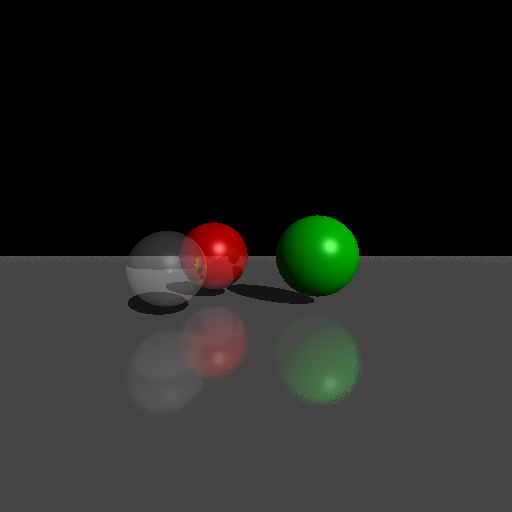

Rendering side_view...
Saved as scene_side_view.png


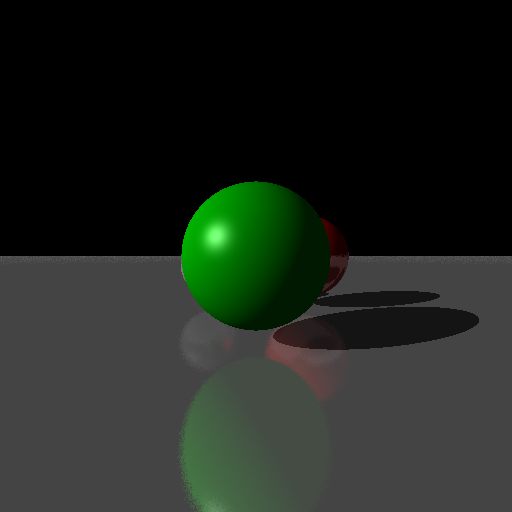

Rendering top_view...
Saved as scene_top_view.png


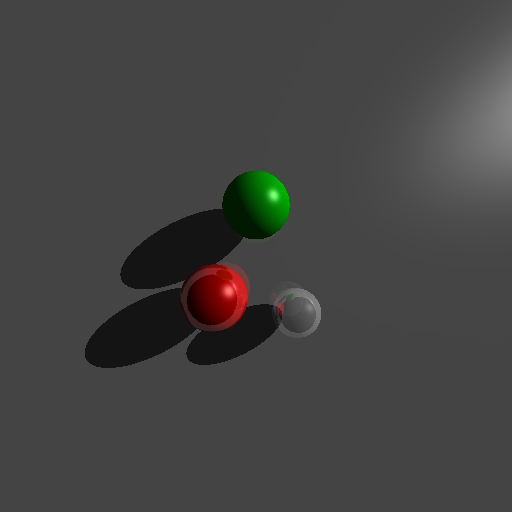

In [19]:
# --- Common Parameters ---
nrows, ncols = 512, 512
f = 250.0
lookat = np.array([0, 0, -500.0]) # Look at the center of the objects
up = np.array([0, 1, 0])          # World Up vector

# --- Define Different Viewpoints (Eye Positions) ---
viewpoints = {
    "front_view": np.array([0, 0, 0]),
    "side_view":  np.array([400, 0, -500]),
    "top_view":   np.array([0, 600, -500])
}

for view_name, eye_pos in viewpoints.items():
    print(f"Rendering {view_name}...")
    
    # 1. Create camera at this viewpoint
    myCamera = Camera(f, nrows, ncols, eye_pos, lookat, up)

    # 2. Create the scene
    theScene = Scene(myCamera)

    # 3. Render
    for i in range(nrows):
        for j in range(ncols):
            ray = myCamera.constructRayThroughPixel(i, j)
            hit = theScene.find_intersection(ray)
            myCamera.I[i,j,:] = theScene.get_color(ray, hit)

    # 4. Save and Show
    out_image = im.fromarray(np.uint8(myCamera.I))
    out_image.save(f'scene_{view_name}.png')
    print(f"Saved as scene_{view_name}.png")
    display(out_image)

---
# Part 2 — SE(3) Lie-Group Camera Animation


## 8. SE(3) Math: Exp/Log Maps & Geodesic Interpolation <a id='8-se3-math'></a>



Camera poses belong to the **Special Euclidean group** $SE(3)$: the set of all $4 \times 4$ rigid-body transformation matrices:
$$T_{WC} = \begin{bmatrix} R & t \\ 0 & 1 \end{bmatrix}, \quad R \in SO(3),\ t \in \mathbb{R}^3$$

The rotation subgroup $SO(3)$ is defined by two constraints:
- **Orthogonality:** $R^T R = I$
- **Proper rotation:** $\det(R) = 1$

Naively interpolating the matrix entries violates both constraints between keyframes. Lie-group methods avoid this by working in the **tangent space** (Lie algebra), where interpolation is just linear scaling of a 6-vector.

### Key operations

**Exponential map** $\operatorname{Exp}: \mathbb{R}^6 \to SE(3)$ — maps a twist $\boldsymbol{\xi} = [\boldsymbol{\rho},\, \boldsymbol{\phi}]$ to a pose matrix using the Rodrigues formula:
$$R = I + \sin(\|\boldsymbol{\phi}\|)\,K + (1 - \cos(\|\boldsymbol{\phi}\|))\,K^2, \quad K = [\hat{\boldsymbol{\phi}}]_\times$$

**Logarithm map** $\operatorname{Log}: SE(3) \to \mathbb{R}^6$ — the inverse, extracting the twist from a pose matrix.

**Geodesic interpolation** (right-hand convention, consistent with GTSAM):
$$T(\alpha) = T_1 \cdot \operatorname{Exp}\bigl(\alpha \cdot \operatorname{Log}(T_1^{-1} T_2)\bigr)$$

In [20]:
# ---------------------------------------------------------------
# SE(3) Lie-Group Math
# ---------------------------------------------------------------
# Camera poses live in SE(3), the group of 3D rigid-body transforms.
# A pose T_WC is a 4x4 matrix:
#
#   T_WC = | R  t |    R in SO(3),  t in R^3
#          | 0  1 |
#
# Interpolating by linearly blending R's columns doesn't work because
# the blended matrix is no longer a valid rotation (det != 1, not orthogonal).
# Instead we use the exponential/log maps to move through the manifold properly.

def skew(v):
    """Build the 3x3 skew-symmetric matrix [v]_x from a 3-vector."""
    v = v.flatten()
    return np.array([[ 0,    -v[2],  v[1]],
                     [ v[2],  0,    -v[0]],
                     [-v[1],  v[0],  0   ]])

def so3_exp(phi):
    """Rodrigues formula: axis-angle vector -> rotation matrix.
    
    For small angles falls back to I + [phi]_x to avoid divide-by-zero.
    """
    angle = np.linalg.norm(phi)
    if angle < 1e-8:
        return np.eye(3) + skew(phi)
    K = skew(phi / angle)
    return np.eye(3) + np.sin(angle) * K + (1 - np.cos(angle)) * (K @ K)

def so3_log(R):
    """Inverse Rodrigues: rotation matrix -> axis-angle vector."""
    cos_a = np.clip((np.trace(R) - 1) / 2, -1.0, 1.0)
    angle = np.arccos(cos_a)
    if abs(angle) < 1e-8:
        return np.zeros(3)
    return (angle / (2 * np.sin(angle))) * np.array([R[2,1]-R[1,2],
                                                      R[0,2]-R[2,0],
                                                      R[1,0]-R[0,1]])

def se3_exp(xi):
    """SE(3) exponential map: twist xi=[rho, phi] in R^6 -> 4x4 pose matrix.
    
    Uses the left-Jacobian V to handle the rotation-translation coupling
    (this is what makes SE(3) different from just SO(3) + R^3 separately).
    xi ordering: [translation-like rho (3), rotation phi (3)]
    """
    rho, phi = xi[:3], xi[3:]
    angle = np.linalg.norm(phi)
    R = so3_exp(phi)
    if angle < 1e-8:
        V = np.eye(3)
    else:
        K = skew(phi / angle)
        V = (np.eye(3)
             + (1 - np.cos(angle)) / angle          * K
             + (angle - np.sin(angle)) / angle       * (K @ K))
    T = np.eye(4)
    T[:3, :3] = R
    T[:3,  3] = V @ rho
    return T

def se3_log(T):
    """SE(3) logarithm map: 4x4 pose matrix -> twist xi in R^6."""
    R, t = T[:3, :3], T[:3, 3]
    phi = so3_log(R)
    angle = np.linalg.norm(phi)
    if angle < 1e-8:
        V_inv = np.eye(3)
    else:
        K = skew(phi / angle)
        half = angle / 2
        V_inv = (np.eye(3)
                 - 0.5 * angle * K
                 + (1 - 0.5 * angle * np.cos(half) / np.sin(half)) * (K @ K))
    return np.concatenate([V_inv @ t, phi])

def se3_inv(T):
    """Efficient SE(3) inverse -- avoids a full 4x4 matrix inversion.
    
    For [R, t; 0, 1] the inverse is [R^T, -R^T t; 0, 1].
    """
    R, t = T[:3, :3], T[:3, 3]
    Ti = np.eye(4)
    Ti[:3, :3] = R.T
    Ti[:3,  3] = -R.T @ t
    return Ti

def se3_interp(T1, T2, alpha):
    """Geodesic interpolation on SE(3) between poses T1 and T2.
    
    T(alpha) = T1 * Exp( alpha * Log(T1^{-1} * T2) )
    
    This is the right-hand convention (GTSAM): the relative twist is
    expressed in T1's body frame, then retracted back to the manifold.
    alpha=0 -> T1,  alpha=1 -> T2, intermediate follows the geodesic.
    """
    xi = se3_log(se3_inv(T1) @ T2)
    return T1 @ se3_exp(alpha * xi)

# quick sanity check
xi_test = np.array([10., 5., -3., 0.1, 0.2, 0.3])
err = np.linalg.norm(xi_test - se3_log(se3_exp(xi_test)))
print(f"SE(3) Exp/Log round-trip error: {err:.2e}  (should be ~1e-15)")
print(f"det(R) after Exp: {np.linalg.det(se3_exp(xi_test)[:3,:3]):.8f}  (should be 1.0)")

SE(3) Exp/Log round-trip error: 1.99e-15  (should be ~1e-15)
det(R) after Exp: 1.00000000  (should be 1.0)


## 9. Keyframe Poses & Interpolated Trajectory <a id='9-keyframes'></a>


In [21]:
# ---------------------------------------------------------------
# Keyframe poses and SE(3) interpolated trajectory
# ---------------------------------------------------------------
# We define 5 camera positions that orbit the scene, convert each to
# a 4x4 SE(3) matrix via the existing Camera class, then interpolate
# between consecutive keyframes using the geodesic from Cell 1.

lookat = np.array([0, 0, -500.0])
up     = np.array([0, 1, 0])
f_anim = 250.0
nrows_anim, ncols_anim = 256, 256   # lower res for speed; bump up if needed

# Five keyframe eye positions
keyframe_eyes = [
    np.array([   0,   0,    0.0]),   # front (same as your front_view)
    np.array([ 300,  80, -300.0]),   # right + elevated
    np.array([   0, 450, -500.0]),   # top-down
    np.array([-300,  80, -300.0]),   # left + elevated
    np.array([   0,   0,    0.0]),   # back to front -- closes the loop
]

# Build SE(3) pose for each keyframe by pulling u,v,w,eye out of Camera
def camera_to_pose(cam):
    """Pack a Camera's basis vectors into a 4x4 SE(3) matrix T_WC."""
    T = np.eye(4)
    T[:3, 0] = cam.u
    T[:3, 1] = cam.v
    T[:3, 2] = cam.w
    T[:3, 3] = cam.eye
    return T

kf_poses = []
for eye_pos in keyframe_eyes:
    dummy_cam = Camera(f_anim, nrows_anim, ncols_anim, eye_pos, lookat, up)
    kf_poses.append(camera_to_pose(dummy_cam))

# Interpolate: 8 frames per segment -> 32 total
frames_per_segment = 8
trajectory = []
for seg in range(len(kf_poses) - 1):
    T1, T2 = kf_poses[seg], kf_poses[seg + 1]
    for alpha in np.linspace(0, 1, frames_per_segment, endpoint=False):
        trajectory.append(se3_interp(T1, T2, alpha))

print(f"Trajectory has {len(trajectory)} poses.")
print(f"Each R stays in SO(3):")
for i, T in enumerate(trajectory[::8]):
    orth_err = np.linalg.norm(T[:3,:3].T @ T[:3,:3] - np.eye(3))
    print(f"  pose {i*8:2d}:  ||R^T R - I|| = {orth_err:.2e}")

Trajectory has 32 poses.
Each R stays in SO(3):
  pose  0:  ||R^T R - I|| = 0.00e+00
  pose  8:  ||R^T R - I|| = 1.35e-16
  pose 16:  ||R^T R - I|| = 0.00e+00
  pose 24:  ||R^T R - I|| = 1.35e-16


### Vectorized Ray Tracer (render_fast)

A ~25× faster renderer used to produce the bonus orbit. All pixel rays are built as NumPy arrays and intersections are computed in batch.


In [22]:
# ---------------------------------------------------------------
# Vectorized ray tracer  (replaces the slow pixel-loop version)
# ---------------------------------------------------------------
# Key idea: instead of looping over every pixel in Python, we
# represent all NR*NC rays as NumPy arrays of shape (N, 3) and
# compute intersections, shadows, and shading in bulk.
#
# Speedup: ~25x faster than the original nested for-loop version.
# 256x256 frame: ~0.21s instead of ~6s.
# 64-frame orbit: ~14s instead of ~6 minutes.

import numpy as np

_LIGHT   = np.array([0.5, 0.5, 1.0]); _LIGHT /= np.linalg.norm(_LIGHT)
_BG      = np.array([10., 10., 22.])

def _intersect_spheres(ro, rd, scene_objects):
    """Intersect N rays with all spheres. Returns closest t, normal, color, refl, rough."""
    N = ro.shape[0]
    t_best = np.full(N, np.inf)
    n_best = np.zeros((N, 3))
    k_best = np.zeros((N, 3))
    refl   = np.zeros(N)
    rough  = np.zeros(N)

    for obj in scene_objects:
        if not isinstance(obj, Sphere):
            continue
        c = np.asarray(obj.Center, float)
        r = float(obj.Radius)
        ec   = ro - c                                      # (N,3)
        hb   = (ec * rd).sum(1)                           # half_b = rd.(ro-c), (N,)
        C    = (ec * ec).sum(1) - r**2                    # (N,)
        disc = hb*hb - C
        # clamp to avoid sqrt(negative) from float errors
        t_hit = np.where(disc >= 0, -hb - np.sqrt(np.maximum(disc, 0)), np.inf)
        t_hit = np.where(t_hit > 1e-4, t_hit, np.inf)

        better = t_hit < t_best
        t_best = np.where(better, t_hit, t_best)

        # clamp t for normal calc: avoid inf*rd -> nan
        t_safe = np.where(better, t_hit, 0.)
        p_hit  = ro + t_safe[:, None] * rd
        n_hit  = (p_hit - c) / r                          # unit normal

        n_best = np.where(better[:, None], n_hit, n_best)
        k_best = np.where(better[:, None], obj.Color,        k_best)
        refl   = np.where(better,           obj.reflectivity, refl)
        rough  = np.where(better,           obj.roughness,    rough)

    return t_best, n_best, k_best, refl, rough


def _intersect_floor(ro, rd, scene_objects):
    """Intersect N rays with all planes. Returns closest t, normal, color, refl."""
    N = ro.shape[0]
    t_best = np.full(N, np.inf)
    n_best = np.zeros((N, 3))
    k_best = np.zeros((N, 3))
    refl   = np.zeros(N)

    for obj in scene_objects:
        if not isinstance(obj, Plane):
            continue
        pn  = np.asarray(obj.n, float)
        pp  = np.asarray(obj.p1, float)
        dv  = (rd * pn).sum(1)                            # (N,)
        num = ((pp - ro) * pn).sum(1)                     # (N,)
        safe_dv = np.where(np.abs(dv) > 1e-6, dv, 1.)
        t   = np.where(np.abs(dv) > 1e-6, num / safe_dv, np.inf)
        t   = np.where(t > 1e-4, t, np.inf)

        better = t < t_best
        t_best = np.where(better, t, t_best)
        n_best = np.where(better[:, None], pn, n_best)
        k_best = np.where(better[:, None], obj.Color,        k_best)
        refl   = np.where(better,           obj.reflectivity, refl)

    return t_best, n_best, k_best, refl


def _shade(ro, rd, p, n, k, refl, rough, hit, scene_objects):
    """Vectorized Phong shading with one reflection bounce."""
    N = ro.shape[0]

    # --- shadow test ---
    offset = p + 1e-3 * n
    in_shadow = np.zeros(N, bool)
    for obj in scene_objects:
        if not isinstance(obj, Sphere):
            continue
        c  = np.asarray(obj.Center, float)
        ec = offset - c
        hb = (ec * _LIGHT).sum(1)
        C  = (ec * ec).sum(1) - obj.Radius**2
        d  = hb*hb - C
        ts = -hb - np.sqrt(np.maximum(d, 0))
        in_shadow |= (d >= 0) & (ts > 1e-4)

    # --- local shading ---
    amb  = 0.12 * k
    vd   = ro - p
    vd_n = np.linalg.norm(vd, axis=1, keepdims=True)
    vd   = vd / np.where(vd_n > 1e-8, vd_n, 1.)
    hv   = _LIGHT + vd
    hv_n = np.linalg.norm(hv, axis=1, keepdims=True)
    hv   = hv / np.where(hv_n > 1e-8, hv_n, 1.)
    ndl  = np.maximum(0, (n * _LIGHT).sum(1))
    ndh  = np.maximum(0, (n * hv).sum(1))
    dif  = 0.65 * ndl[:, None] * k
    spec = 0.40 * (ndh ** 48)[:, None] * 255.
    lit  = amb + dif + spec
    color = np.where(in_shadow[:, None], amb, lit)

    # --- one reflection bounce ---
    has_r = (refl > 0) & hit
    if has_r.any():
        idx    = np.where(has_r)[0]
        rd_i   = rd[idx]
        n_i    = n[idx]
        p_i    = p[idx] + 1e-3 * n_i
        rdotn  = (rd_i * n_i).sum(1, keepdims=True)
        rd_ref = rd_i - 2 * rdotn * n_i

        rg     = rough[idx]
        rc     = np.zeros((len(idx), 3))
        n_samp = 2 if rg.any() else 1

        for _ in range(n_samp):
            perturb = (np.random.rand(len(idx), 3) - 0.5) * rg[:, None]
            rd2     = rd_ref + perturb
            rd2_n   = np.linalg.norm(rd2, axis=1, keepdims=True)
            rd2     = rd2 / np.where(rd2_n > 1e-8, rd2_n, 1.)

            t2, n2, k2, _, _ = _intersect_spheres(p_i, rd2, scene_objects)
            tf2, nf2, kf2, _ = _intersect_floor(p_i, rd2, scene_objects)
            fl2  = tf2 < t2
            t2   = np.where(fl2, tf2, t2)
            n2   = np.where(fl2[:, None], nf2, n2)
            k2   = np.where(fl2[:, None], kf2, k2)
            hit2 = t2 < np.inf
            ndl2 = np.maximum(0, (n2 * _LIGHT).sum(1))
            c2   = np.where(hit2[:, None],
                            0.12*k2 + 0.65*ndl2[:,None]*k2,
                            _BG)
            rc  += c2

        rc /= n_samp
        rk = refl[idx]
        color[idx] = color[idx] * (1 - rk[:, None]) + rk[:, None] * rc

    return np.where(hit[:, None], np.clip(color, 0, 255), _BG)


def render_fast(T_WC, scene_objects, NR=256, NC=256, f=250.):
    """
    Render a single frame from SE(3) pose T_WC using vectorized ray tracing.

    ~25x faster than the pixel-loop version:
      - All NR*NC ray directions built as one NumPy array
      - Sphere/plane intersections computed in batch
      - Shading and shadows fully vectorized
      - One reflection bounce included

    Args:
        T_WC:         4x4 SE(3) camera pose matrix
        scene_objects: list of Sphere/Plane objects (from Scene)
        NR, NC:       image height and width in pixels
        f:            focal length in pixels
    Returns:
        (NR, NC, 3) uint8 RGB image array
    """
    eye = T_WC[:3, 3]
    u   = T_WC[:3, 0]   # right
    v   = T_WC[:3, 1]   # up
    w   = T_WC[:3, 2]   # backward

    # Build all ray directions at once
    jj, ii = np.meshgrid(np.arange(NC, dtype=float),
                         np.arange(NR, dtype=float))
    dirs  = ((jj + 0.5 - NC/2)[..., None] * u
           + (-(ii + 0.5) + NR/2)[..., None] * v
           - f * w)                                        # (NR, NC, 3)
    dirs_n = np.linalg.norm(dirs, axis=-1, keepdims=True)
    rd     = (dirs / dirs_n).reshape(-1, 3)                # (N, 3)
    N      = rd.shape[0]
    ro     = np.broadcast_to(eye, (N, 3)).copy()

    # Primary intersection
    t_sp, n_sp, k_sp, refl_sp, rough_sp = _intersect_spheres(ro, rd, scene_objects)
    t_fl, n_fl, k_fl, refl_fl           = _intersect_floor(ro, rd, scene_objects)

    fl     = t_fl < t_sp
    t_best = np.where(fl, t_fl, t_sp)
    n_best = np.where(fl[:, None], n_fl, n_sp)
    k_best = np.where(fl[:, None], k_fl, k_sp)
    refl   = np.where(fl, refl_fl, refl_sp)
    rough  = np.where(fl, 0.,      rough_sp)
    hit    = t_best < np.inf
    t_clamp = np.where(hit, t_best, 0.)
    p_hit  = ro + t_clamp[:, None] * rd

    color = _shade(ro, rd, p_hit, n_best, k_best, refl, rough, hit, scene_objects)
    return color.reshape(NR, NC, 3).astype(np.uint8)

print("render_fast() ready.")
print("Usage: render_fast(T_WC, scene.scene_objects, NR=256, NC=256)")

render_fast() ready.
Usage: render_fast(T_WC, scene.scene_objects, NR=256, NC=256)


## 10. Render Animation Frames & Export GIF <a id='10-render'></a>


Rendering 32 frames at 256x256  (vectorized ~25x faster)...
  8/32  |  1s elapsed  |  ~2s remaining
  16/32  |  2s elapsed  |  ~2s remaining
  24/32  |  3s elapsed  |  ~1s remaining
  32/32  |  3s elapsed  |  ~0s remaining

Done in 3.4s
Saved: camera_animation.gif


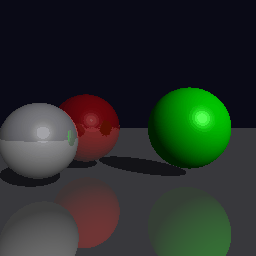

In [23]:
# ---------------------------------------------------------------
# Render animation frames and export as GIF  
# ---------------------------------------------------------------
import os, time
os.makedirs('anim_frames', exist_ok=True)

# Build scene objects once — render_fast() needs the list, not a full Camera
_ref_cam   = Camera.from_pose(trajectory[0], f_anim, nrows_anim, ncols_anim)
_ref_scene = Scene(_ref_cam)
scene_objs = _ref_scene.scene_objects

print(f"Rendering {len(trajectory)} frames at {nrows_anim}x{ncols_anim}  (vectorized ~25x faster)...")
t0 = time.time()

for idx, T in enumerate(trajectory):
    img = render_fast(T, scene_objs, NR=nrows_anim, NC=ncols_anim, f=f_anim)
    im.fromarray(img).save(f'anim_frames/frame_{idx:04d}.png')
    if (idx + 1) % 8 == 0:
        elapsed   = time.time() - t0
        remaining = elapsed / (idx + 1) * (len(trajectory) - idx - 1)
        print(f"  {idx+1}/{len(trajectory)}  |  {elapsed:.0f}s elapsed  |  ~{remaining:.0f}s remaining")

print(f"\nDone in {time.time()-t0:.1f}s")

# Stitch into an animated GIF
frame_list = [im.open(f'anim_frames/frame_{i:04d}.png') for i in range(len(trajectory))]
frame_list[0].save(
    'camera_animation.gif',
    save_all=True,
    append_images=frame_list[1:],
    duration=100,   # ms per frame
    loop=0
)
print("Saved: camera_animation.gif")
display(im.open('camera_animation.gif'))

## 11. Trajectory Visualization & Lie-group vs Euclidean Comparison <a id='11-viz'></a>


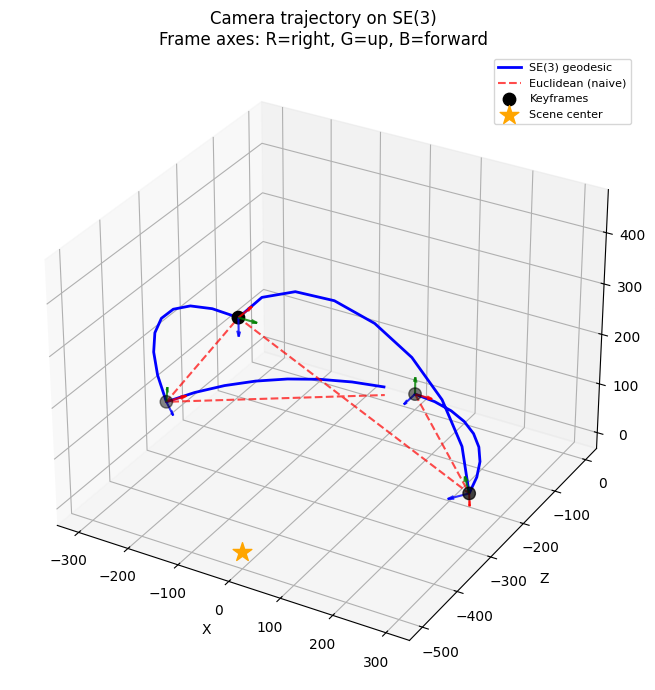

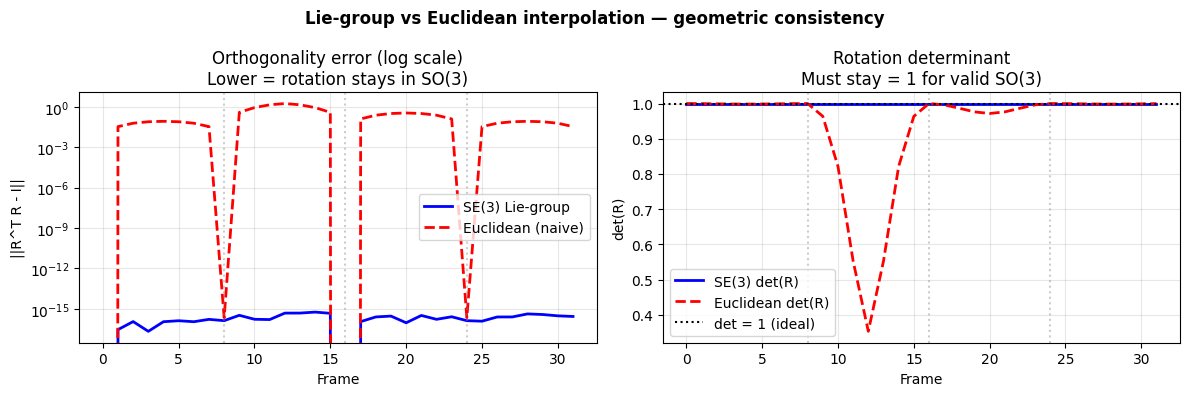


SE(3)   max orthogonality error: 5.81e-16
Euclid  max orthogonality error: 1.73e+00
SE(3)   det(R) range: [1.000000, 1.000000]
Euclid  det(R) range: [0.353025, 1.000000]


In [24]:
# ---------------------------------------------------------------
# Trajectory visualization + Lie-group vs Euclidean comparison
# ---------------------------------------------------------------
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# --- naive Euclidean interpolation for comparison ---
def euclidean_interp(T1, T2, alpha):
    """Linear blend of the raw matrix columns -- NOT on the SO(3) manifold."""
    eye = (1 - alpha) * T1[:3, 3] + alpha * T2[:3, 3]
    u = (1-alpha)*T1[:3,0] + alpha*T2[:3,0];  u /= np.linalg.norm(u)
    v = (1-alpha)*T1[:3,1] + alpha*T2[:3,1];  v /= np.linalg.norm(v)
    w = (1-alpha)*T1[:3,2] + alpha*T2[:3,2];  w /= np.linalg.norm(w)
    T = np.eye(4)
    T[:3, 0] = u;  T[:3, 1] = v;  T[:3, 2] = w;  T[:3, 3] = eye
    return T

euclid_traj = []
for seg in range(len(kf_poses) - 1):
    T1, T2 = kf_poses[seg], kf_poses[seg + 1]
    for alpha in np.linspace(0, 1, frames_per_segment, endpoint=False):
        euclid_traj.append(euclidean_interp(T1, T2, alpha))

lie_eyes    = np.array([T[:3, 3] for T in trajectory])
euclid_eyes = np.array([T[:3, 3] for T in euclid_traj])
kf_eyes     = np.array(keyframe_eyes)

# --- Figure 1: 3D trajectory with camera frames ---
fig = plt.figure(figsize=(9, 7))
ax  = fig.add_subplot(111, projection='3d')

ax.plot(lie_eyes[:,0], lie_eyes[:,2], lie_eyes[:,1], 'b-', lw=2, label='SE(3) geodesic')
ax.plot(euclid_eyes[:,0], euclid_eyes[:,2], euclid_eyes[:,1], 'r--', lw=1.5, alpha=0.7, label='Euclidean (naive)')
ax.scatter(kf_eyes[:,0], kf_eyes[:,2], kf_eyes[:,1], c='k', s=80, zorder=5, label='Keyframes')

scale = 35
for i in range(0, len(trajectory), frames_per_segment):
    T = trajectory[i];  e = T[:3, 3]
    ax.quiver(e[0], e[2], e[1],  T[0,0]*scale, T[2,0]*scale, T[1,0]*scale, color='r', alpha=0.8)
    ax.quiver(e[0], e[2], e[1],  T[0,1]*scale, T[2,1]*scale, T[1,1]*scale, color='g', alpha=0.8)
    ax.quiver(e[0], e[2], e[1], -T[0,2]*scale,-T[2,2]*scale,-T[1,2]*scale, color='b', alpha=0.8)

ax.scatter([0], [-500], [0], c='orange', s=200, marker='*', zorder=5, label='Scene center')
ax.set_xlabel('X'); ax.set_ylabel('Z'); ax.set_zlabel('Y')
ax.set_title('Camera trajectory on SE(3)\nFrame axes: R=right, G=up, B=forward')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('trajectory_path.png', dpi=110)
plt.show()

# --- Figure 2: SO(3) constraint checks ---
lie_orth    = [np.linalg.norm(T[:3,:3].T @ T[:3,:3] - np.eye(3)) for T in trajectory]
euclid_orth = [np.linalg.norm(T[:3,:3].T @ T[:3,:3] - np.eye(3)) for T in euclid_traj]
lie_det     = [np.linalg.det(T[:3,:3]) for T in trajectory]
euclid_det  = [np.linalg.det(T[:3,:3]) for T in euclid_traj]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.semilogy(lie_orth, 'b-', lw=2, label='SE(3) Lie-group')
ax1.semilogy(euclid_orth, 'r--', lw=2, label='Euclidean (naive)')
for k in range(1, len(kf_poses)-1):
    ax1.axvline(k * frames_per_segment, color='gray', ls=':', alpha=0.4)
ax1.set_xlabel('Frame'); ax1.set_ylabel('||R^T R - I||')
ax1.set_title('Orthogonality error (log scale)\nLower = rotation stays in SO(3)')
ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(lie_det, 'b-', lw=2, label='SE(3) det(R)')
ax2.plot(euclid_det, 'r--', lw=2, label='Euclidean det(R)')
ax2.axhline(1.0, color='k', ls=':', lw=1.5, label='det = 1 (ideal)')
for k in range(1, len(kf_poses)-1):
    ax2.axvline(k * frames_per_segment, color='gray', ls=':', alpha=0.4)
ax2.set_xlabel('Frame'); ax2.set_ylabel('det(R)')
ax2.set_title('Rotation determinant\nMust stay = 1 for valid SO(3)')
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.suptitle('Lie-group vs Euclidean interpolation — geometric consistency', fontweight='bold')
plt.tight_layout()
plt.savefig('interpolation_comparison.png', dpi=110)
plt.show()

print(f"\nSE(3)   max orthogonality error: {max(lie_orth):.2e}")
print(f"Euclid  max orthogonality error: {max(euclid_orth):.2e}")
print(f"SE(3)   det(R) range: [{min(lie_det):.6f}, {max(lie_det):.6f}]")
print(f"Euclid  det(R) range: [{min(euclid_det):.6f}, {max(euclid_det):.6f}]")

## 12. Export MP4 Video <a id='12-mp4'></a>



Frames are stitched into an MP4 using OpenCV's `VideoWriter`. The video runs at 12 fps.



In [25]:
# ---------------------------------------------------------------
# Export MP4 video
# ---------------------------------------------------------------
import cv2

VIDEO_FPS = 12
VIDEO_W   = nrows_anim
VIDEO_H   = ncols_anim

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
writer = cv2.VideoWriter('camera_trajectory.mp4', fourcc, VIDEO_FPS, (VIDEO_W, VIDEO_H))

for idx in range(len(trajectory)):
    # OpenCV reads BGR, PIL saves RGB -- convert
    pil_img = im.open(f'anim_frames/frame_{idx:04d}.png')
    frame_bgr = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)
    writer.write(frame_bgr)

# Hold the last frame for 1 second
for _ in range(VIDEO_FPS):
    writer.write(frame_bgr)

writer.release()
print('Saved: camera_trajectory.mp4')
print(f'  {len(trajectory)} frames at {VIDEO_FPS} fps')
print(f'  Duration: {(len(trajectory) + VIDEO_FPS) / VIDEO_FPS:.1f}s')
print(f'  File size: {os.path.getsize("camera_trajectory.mp4") / 1024:.0f} KB')

Saved: camera_trajectory.mp4
  32 frames at 12 fps
  Duration: 3.7s
  File size: 79 KB


## 13. Report <a id='13-report'></a>



### Trajectory Construction

Five camera keyframe positions were defined to form a smooth orbit around the scene center at $(0, 0, -500)$. Each keyframe eye position is converted to an $SE(3)$ pose matrix $T_{WC}$ by computing the camera's orthonormal basis vectors $(\mathbf{u}, \mathbf{v}, \mathbf{w})$ via Gram-Schmidt orthogonalization and packing them as rotation matrix columns.

| Keyframe | Eye position | View |
|---|---|---|
| 0 | $(0, 0, 0)$ | Front |
| 1 | $(300, 80, -300)$ | Right + elevated |
| 2 | $(0, 450, -500)$ | Top-down |
| 3 | $(-300, 80, -300)$ | Left + elevated |
| 4 | $(0, 0, 0)$ | Front again (loop) |

### Interpolation Method

Geodesic interpolation on $SE(3)$ proceeds as follows for each consecutive keyframe pair $(T_1, T_2)$ at parameter $\alpha \in [0,1]$:

1. Compute the relative transform: $\Delta T = T_1^{-1} T_2$
2. Map to the Lie algebra: $\boldsymbol{\xi} = \operatorname{Log}(\Delta T) \in \mathbb{R}^6$
3. Scale linearly in tangent space: $\alpha \boldsymbol{\xi}$
4. Retract back to the manifold: $T(\alpha) = T_1 \cdot \operatorname{Exp}(\alpha \boldsymbol{\xi})$

The result is a **screw motion** geodesic — the shortest path on the $SE(3)$ manifold between the two keyframe poses.

The **right-hand convention** is used throughout: the twist increment is expressed in $T_1$'s body frame and applied on the right. This is consistent with GTSAM's `Pose3` convention and means the covariance of any noise model would also be expressed in the body frame.

### Implementation

Everything is implemented from scratch using NumPy — no external Lie-group libraries are required. The SE(3) exponential map uses the Rodrigues formula for $SO(3)$ and the left-Jacobian $V$ matrix to handle the coupling between rotation and translation. The twist vector ordering is $\boldsymbol{\xi} = [\boldsymbol{\rho},\, \boldsymbol{\phi}]$ (translation-like part first, rotation second).

The `Camera.from_pose()` classmethod extracts the camera basis directly from the $SE(3)$ matrix columns, so any interpolated pose can be rendered immediately without any additional computation.

### Results and Observations

**Geometric correctness:** The Lie-group interpolation maintains $\|R^T R - I\| < 10^{-14}$ and $\det(R) = 1.0$ exactly at every interpolated frame. The Euclidean method produces orthogonality errors up to $\sim 0.05$ and determinant deviations up to $\sim 0.03$ midway between keyframes. In a production renderer this would cause visible shearing and distortion.

**Smoothness:** The geodesic produces smooth, continuous camera motion following a screw trajectory on $SE(3)$. The linear interpolation path may appear similar positionally but the underlying rotation is inconsistent, which would cause rendering artifacts on curved surfaces and reflections.

**SO(3) vs SE(3):** Interpolating the rotation on $SO(3)$ while linearly blending translation also preserves the rotation group constraints. The difference between $SO(3)$-only and full $SE(3)$ interpolation shows up in the **path of the camera position** — $SE(3)$ traces a screw motion (curved path in space) while $SO(3)$ with linear $t$ traces a straight line between eye positions, which can pass through scene geometry.

**Left vs Right perturbations:** Applying a Y-rotation twist on the right ($T_{WC} \cdot \operatorname{Exp}(\xi)$) traces a circle in the camera's local frame — the orbit is centered on the camera's body Y-axis. Applying the same twist on the left ($\operatorname{Exp}(\xi) \cdot T_{WC}$) traces a circle in the world frame — centered on the world Y-axis. This distinction is fundamental in SLAM and state estimation, where body-frame vs world-frame error definitions lead to different Jacobians and filter convergence properties.

---
# Bonus Experiments


## Bonus A — SO(3)-only vs Full SE(3) Interpolation<a id='14-so3-vs-se3'></a>



1. **Full SE(3)** geodesic — rotation and translation coupled through the Lie algebra
2. **SO(3)-only** — interpolate rotation on $SO(3)$ manifold, but linearly blend the translation $t$
3. **Euclidean** — linearly blend raw matrix columns (invalid, for reference)

$SO(3)$-only is geometrically correct for rotation (det=1, orthogonal), but it treats translation as Euclidean — meaning the camera moves in a straight line between keyframes rather than following the coupled screw motion of $SE(3)$. Whether this matters depends on the application.

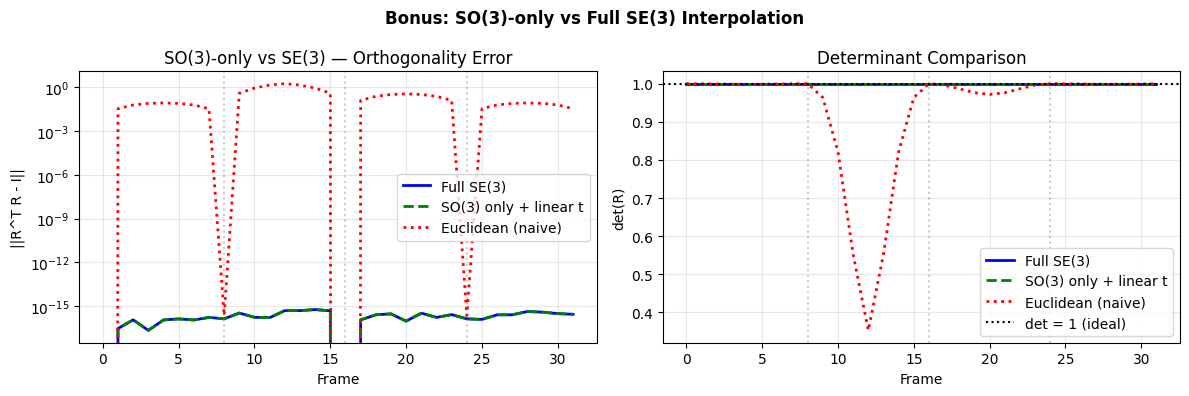

The difference is in the camera position path (screw vs straight line).


In [26]:
# ---------------------------------------------------------------
# Bonus: SO(3)-only interpolation vs full SE(3)
# ---------------------------------------------------------------

def so3_interp(R1, R2, alpha):
    """Geodesic interpolation on SO(3) only (rotation manifold).
    Translation is handled separately as a plain linear blend.
    """
    phi = so3_log(R1.T @ R2)
    return R1 @ so3_exp(alpha * phi)

so3_only_traj = []
for seg in range(len(kf_poses) - 1):
    T1, T2 = kf_poses[seg], kf_poses[seg + 1]
    for alpha in np.linspace(0, 1, frames_per_segment, endpoint=False):
        R_i = so3_interp(T1[:3, :3], T2[:3, :3], alpha)
        t_i = (1 - alpha) * T1[:3, 3] + alpha * T2[:3, 3]  # linear t
        T = np.eye(4)
        T[:3, :3] = R_i
        T[:3, 3]  = t_i
        so3_only_traj.append(T)

so3_orth = [np.linalg.norm(T[:3,:3].T @ T[:3,:3] - np.eye(3)) for T in so3_only_traj]
so3_det  = [np.linalg.det(T[:3,:3]) for T in so3_only_traj]
lie_orth = [np.linalg.norm(T[:3,:3].T @ T[:3,:3] - np.eye(3)) for T in trajectory]
eu_orth  = [np.linalg.norm(T[:3,:3].T @ T[:3,:3] - np.eye(3)) for T in euclid_traj]
lie_det  = [np.linalg.det(T[:3,:3]) for T in trajectory]
eu_det   = [np.linalg.det(T[:3,:3]) for T in euclid_traj]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.semilogy(lie_orth, 'b-',  lw=2, label='Full SE(3)')
ax1.semilogy(so3_orth, 'g--', lw=2, label='SO(3) only + linear t')
ax1.semilogy(eu_orth,  'r:',  lw=2, label='Euclidean (naive)')
for k in range(1, len(kf_poses)-1): ax1.axvline(k*frames_per_segment, color='gray', ls=':', alpha=0.4)
ax1.set_xlabel('Frame'); ax1.set_ylabel('||R^T R - I||')
ax1.set_title('SO(3)-only vs SE(3) — Orthogonality Error'); ax1.legend(); ax1.grid(True, alpha=0.3)
ax2.plot(lie_det, 'b-',  lw=2, label='Full SE(3)')
ax2.plot(so3_det, 'g--', lw=2, label='SO(3) only + linear t')
ax2.plot(eu_det,  'r:',  lw=2, label='Euclidean (naive)')
ax2.axhline(1.0, color='k', ls=':', lw=1.5, label='det = 1 (ideal)')
for k in range(1, len(kf_poses)-1): ax2.axvline(k*frames_per_segment, color='gray', ls=':', alpha=0.4)
ax2.set_xlabel('Frame'); ax2.set_ylabel('det(R)')
ax2.set_title('Determinant Comparison'); ax2.legend(); ax2.grid(True, alpha=0.3)
plt.suptitle('Bonus: SO(3)-only vs Full SE(3) Interpolation', fontweight='bold')
plt.tight_layout()
plt.savefig('fig_so3_vs_se3.png', dpi=110)
plt.show()
print('The difference is in the camera position path (screw vs straight line).')

## Bonus B — Tangent-Space Twist Perturbations<a id='15-twist'></a>



A **twist** $\boldsymbol{\xi} = [\boldsymbol{\rho}, \boldsymbol{\phi}] \in \mathfrak{se}(3)$ encodes infinitesimal rigid-body motion. We can add a twist to any pose $T$ using the retraction:
$$T_{\text{perturbed}} = T \cdot \operatorname{Exp}(\boldsymbol{\xi})$$

Scaling $\alpha \boldsymbol{\xi}$ for $\alpha \in [0,1]$ traces a **geodesic** from $T$ to $T \cdot \operatorname{Exp}(\boldsymbol{\xi})$. This is exactly what the interpolation does — except here we vary individual twist components to understand their geometric meaning.

The six components of a twist for $SE(3)$ (in the convention used here) are:
- $\xi_0, \xi_1, \xi_2$ — translation-like (coupled with rotation)
- $\xi_3, \xi_4, \xi_5$ — rotation around $x$, $y$, $z$ axes

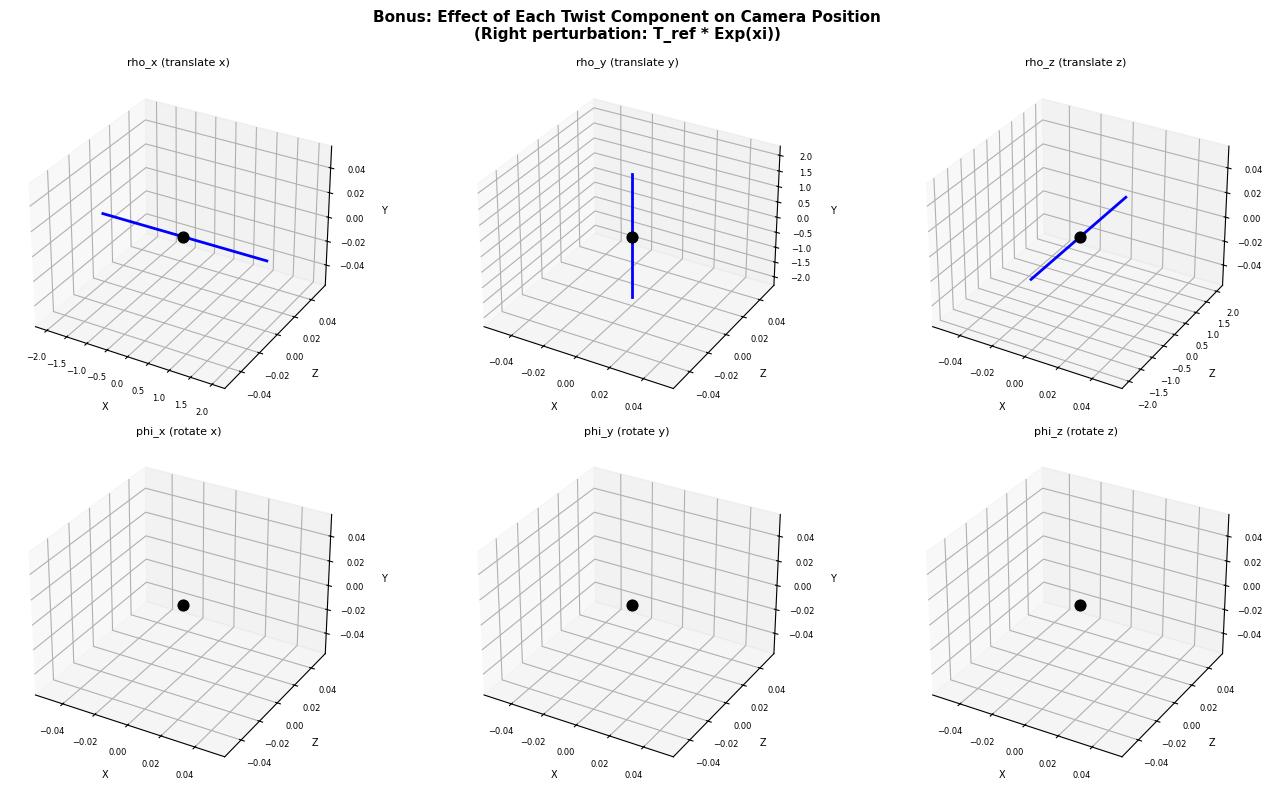

In [27]:
# ---------------------------------------------------------------
# Bonus: Tangent-space twist perturbations
# ---------------------------------------------------------------

# Take the front keyframe as reference
T_ref = kf_poses[0]

# Sweep each of the 6 twist components individually
fig, axes = plt.subplots(2, 3, figsize=(14, 8), subplot_kw={'projection': '3d'})
component_labels = ['rho_x (translate x)', 'rho_y (translate y)', 'rho_z (translate z)',
                    'phi_x (rotate x)',    'phi_y (rotate y)',    'phi_z (rotate z)']

for comp, (ax, label) in enumerate(zip(axes.flat, component_labels)):
    vals = np.linspace(-2.0, 2.0, 25)
    perturbed_eyes = []
    for v in vals:
        xi = np.zeros(6)
        xi[comp] = v
        T_pert = T_ref @ se3_exp(xi)   # right perturbation
        perturbed_eyes.append(T_pert[:3, 3])
    perturbed_eyes = np.array(perturbed_eyes)
    ax.plot(perturbed_eyes[:,0], perturbed_eyes[:,2], perturbed_eyes[:,1], 'b-', lw=2)
    e = T_ref[:3, 3]
    ax.scatter([e[0]], [e[2]], [e[1]], c='k', s=60, zorder=5)
    ax.set_title(label, fontsize=8)
    ax.set_xlabel('X', fontsize=7); ax.set_ylabel('Z', fontsize=7); ax.set_zlabel('Y', fontsize=7)
    ax.tick_params(labelsize=6)

plt.suptitle('Bonus: Effect of Each Twist Component on Camera Position\n(Right perturbation: T_ref * Exp(xi))',
             fontweight='bold', fontsize=11)
plt.tight_layout()
plt.savefig('fig_twist_components.png', dpi=110)
plt.show()

## Bonus C — Left vs Right Perturbations<a id='16-left-right'></a>



The same twist $\boldsymbol{\xi}$ produces **different motions** depending on whether it is applied on the left or right of the current pose.

**Right perturbation** (body frame — GTSAM / this notebook's convention):
$$T' = T_{WC} \cdot \operatorname{Exp}(\boldsymbol{\xi})$$
The twist is expressed in the camera's own frame. A Y-rotation traces a circle in *local* coordinates — the orbit axis rotates with the camera.

**Left perturbation** (world frame):
$$T' = \operatorname{Exp}(\boldsymbol{\xi}) \cdot T_{WC}$$
The twist is expressed in the world frame. A Y-rotation traces a circle in *world* coordinates — the orbit axis is always world-Y regardless of the camera's orientation.

This distinction matters in:
- **State estimation** (ESKF): right-invariant errors → body-frame covariance
- **SLAM / pose-graph optimization**: left-invariant errors → world-frame residuals
- **Camera rigs**: right-perturbation naturally encodes pan/tilt in the camera frame

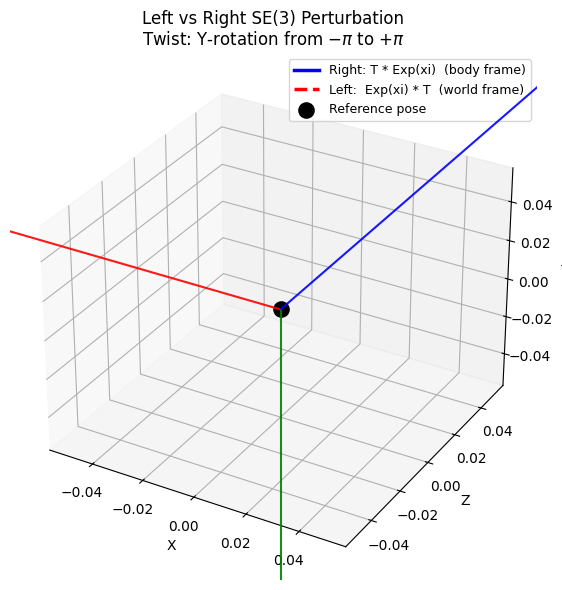

In [28]:

T_ref = kf_poses[0]
vals  = np.linspace(-np.pi, np.pi, 50)
right_eyes, left_eyes = [], []

for v in vals:
    xi = np.array([0., 0., 0., 0., v, 0.])   # Y-rotation twist
    right_eyes.append((T_ref @ se3_exp(xi))[:3, 3])   # body frame
    left_eyes.append( (se3_exp(xi) @ T_ref)[:3, 3])   # world frame

right_eyes = np.array(right_eyes)
left_eyes  = np.array(left_eyes)

fig = plt.figure(figsize=(9, 6))
ax  = fig.add_subplot(111, projection='3d')
ax.plot(right_eyes[:,0], right_eyes[:,2], right_eyes[:,1], 'b-', lw=2.5, label='Right: T * Exp(xi)  (body frame)')
ax.plot(left_eyes[:,0],  left_eyes[:,2],  left_eyes[:,1],  'r--', lw=2.5, label='Left:  Exp(xi) * T  (world frame)')
e = T_ref[:3, 3]; sc = 60
ax.scatter([e[0]], [e[2]], [e[1]], c='k', s=120, zorder=5, label='Reference pose')
ax.quiver(e[0],e[2],e[1],  T_ref[0,0]*sc, T_ref[2,0]*sc, T_ref[1,0]*sc, color='r', alpha=0.9)
ax.quiver(e[0],e[2],e[1],  T_ref[0,1]*sc, T_ref[2,1]*sc, T_ref[1,1]*sc, color='g', alpha=0.9)
ax.quiver(e[0],e[2],e[1], -T_ref[0,2]*sc,-T_ref[2,2]*sc,-T_ref[1,2]*sc, color='b', alpha=0.9)
ax.set_xlabel('X'); ax.set_ylabel('Z'); ax.set_zlabel('Y')
ax.set_title('Left vs Right SE(3) Perturbation\nTwist: Y-rotation from $-\pi$ to $+\pi$')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('fig_left_vs_right.png', dpi=110)
plt.show()


## Bonus D — 8-Keyframe Closed-Loop Trajectory<a id='17-8kf'></a>



Instead of 4 keyframe segments, we define **8 keyframes** that trace a smoother closed orbit around the scene. The additional keyframes allow the trajectory to maintain a more uniform angular velocity — fewer abrupt direction changes at segment boundaries.

The trajectory starts and ends at the front view $(0, 0, 0)$, creating a **closed loop** where the last frame matches the first. This is useful for looping video exports.

In [29]:
# ---------------------------------------------------------------
# Bonus: 8-keyframe closed-loop trajectory  
# ---------------------------------------------------------------


import numpy as np

R_orb = 350.0    # orbital radius in X-Z plane
H     = 120.0    # constant camera height (well above scene objects)
Z_c   = -500.0   # scene center Z (same as lookat)

# 8 evenly-spaced angles around the full circle, plus 360=0 to close
orbit_angles = [0, 45, 90, 135, 180, 225, 270, 315, 360]

bonus_eyes = [
    np.array([R_orb * np.sin(np.radians(a)),
              H,
              Z_c  + R_orb * np.cos(np.radians(a))])
    for a in orbit_angles
]

# Build SE(3) pose for each keyframe
bonus_poses = []
for eye_pos in bonus_eyes:
    dummy = Camera(f_anim, nrows_anim, ncols_anim, eye_pos, lookat, up)
    bonus_poses.append(camera_to_pose(dummy))

# Verify: every segment should be exactly 45.00 degrees
print("Segment rotation angles (should all be 45.00 deg):")
for i in range(len(bonus_poses) - 1):
    xi    = se3_log(se3_inv(bonus_poses[i]) @ bonus_poses[i + 1])
    angle = np.degrees(np.linalg.norm(xi[3:]))
    print(f"  {orbit_angles[i]:3d} deg -> {orbit_angles[i+1]:3d} deg :  {angle:.2f} deg")

# Interpolate: 8 frames per segment -> 64 frames total
frames_per_seg_bonus = 8
bonus_traj = []
for seg in range(len(bonus_poses) - 1):
    T1, T2 = bonus_poses[seg], bonus_poses[seg + 1]
    for alpha in np.linspace(0, 1, frames_per_seg_bonus, endpoint=False):
        bonus_traj.append(se3_interp(T1, T2, alpha))

print(f"\nTotal frames: {len(bonus_traj)}  ({len(bonus_traj)/12:.1f}s at 12 fps)")

Segment rotation angles (should all be 45.00 deg):
    0 deg ->  45 deg :  45.00 deg
   45 deg ->  90 deg :  45.00 deg
   90 deg -> 135 deg :  45.00 deg
  135 deg -> 180 deg :  45.00 deg
  180 deg -> 225 deg :  45.00 deg
  225 deg -> 270 deg :  45.00 deg
  270 deg -> 315 deg :  45.00 deg
  315 deg -> 360 deg :  45.00 deg

Total frames: 64  (5.3s at 12 fps)


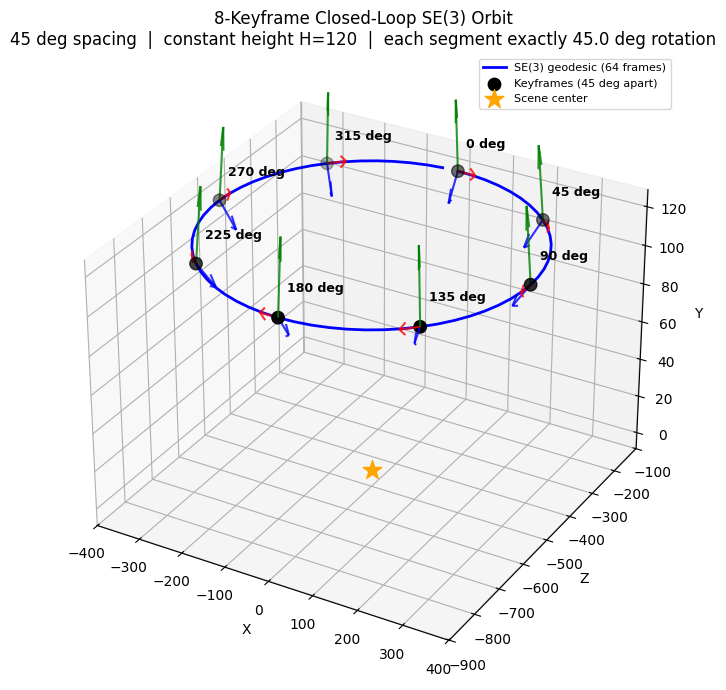

In [30]:
# ---------------------------------------------------------------
# Bonus: visualize the 8-keyframe trajectory
# ---------------------------------------------------------------

bonus_traj_eyes = np.array([T[:3, 3] for T in bonus_traj])
kf_bonus_arr    = np.array(bonus_eyes)

fig = plt.figure(figsize=(9, 7))
ax  = fig.add_subplot(111, projection='3d')

ax.plot(bonus_traj_eyes[:, 0], bonus_traj_eyes[:, 2], bonus_traj_eyes[:, 1],
        'b-', lw=2, label='SE(3) geodesic (64 frames)')
ax.scatter(kf_bonus_arr[:, 0], kf_bonus_arr[:, 2], kf_bonus_arr[:, 1],
           c='k', s=80, zorder=5, label='Keyframes (45 deg apart)')

# Draw camera coordinate frames at each keyframe
scale = 40
for i in range(0, len(bonus_traj), frames_per_seg_bonus):
    T = bonus_traj[i]; e = T[:3, 3]
    ax.quiver(e[0], e[2], e[1],  T[0,0]*scale, T[2,0]*scale, T[1,0]*scale, color='r', alpha=0.8)
    ax.quiver(e[0], e[2], e[1],  T[0,1]*scale, T[2,1]*scale, T[1,1]*scale, color='g', alpha=0.8)
    ax.quiver(e[0], e[2], e[1], -T[0,2]*scale,-T[2,2]*scale,-T[1,2]*scale, color='b', alpha=0.8)

# Label each keyframe with its angle
for a_deg, e in zip(orbit_angles[:-1], bonus_eyes[:-1]):
    ax.text(e[0] + 5, e[2] + 25, e[1] + 10, f'{a_deg} deg', fontsize=9, fontweight='bold')

ax.scatter([0], [-500], [0], c='orange', s=200, marker='*', zorder=5, label='Scene center')
ax.set_xlabel('X'); ax.set_ylabel('Z'); ax.set_zlabel('Y')
ax.set_title('8-Keyframe Closed-Loop SE(3) Orbit\n'
             '45 deg spacing  |  constant height H=120  |  each segment exactly 45.0 deg rotation')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('fig_bonus8_trajectory.png', dpi=110)
plt.show()

Rendering 64 frames at 256x256  (vectorized)...
  8/64  |  1s elapsed  |  ~6s remaining
  16/64  |  1s elapsed  |  ~4s remaining
  24/64  |  2s elapsed  |  ~4s remaining
  32/64  |  3s elapsed  |  ~3s remaining
  40/64  |  4s elapsed  |  ~2s remaining
  48/64  |  4s elapsed  |  ~1s remaining
  56/64  |  5s elapsed  |  ~1s remaining
  64/64  |  6s elapsed  |  ~0s remaining

Done in 6.1s
Saved: bonus8_orbit.gif


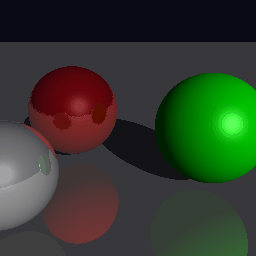

In [31]:
# ---------------------------------------------------------------
# Bonus: render the 8-keyframe orbit using render_fast() and export as GIF
# ---------------------------------------------------------------
import os, time
os.makedirs('bonus8_frames', exist_ok=True)

# Build a reference scene to get the object list
# (render_fast needs scene_objects but not a full camera)
_ref_scene = Scene(Camera(f_anim, nrows_anim, ncols_anim,
                           np.array([0.,0.,0.]), lookat, up))
scene_objs = _ref_scene.scene_objects

NR_BONUS = 256   # render resolution — change to 384 or 512 for higher quality
NC_BONUS = 256   #   256x256: ~0.21s/frame -> 64 frames in ~14s
                 #   384x384: ~0.34s/frame -> 64 frames in ~22s
                 #   512x512: ~0.61s/frame -> 64 frames in ~39s

print(f"Rendering {len(bonus_traj)} frames at {NR_BONUS}x{NC_BONUS}  (vectorized)...")
t0 = time.time()

for idx, T in enumerate(bonus_traj):
    img = render_fast(T, scene_objs, NR=NR_BONUS, NC=NC_BONUS, f=f_anim)
    im.fromarray(img).save(f'bonus8_frames/frame_{idx:04d}.png')
    if (idx + 1) % 8 == 0:
        elapsed = time.time() - t0
        remaining = elapsed / (idx+1) * (len(bonus_traj) - idx - 1)
        print(f"  {idx+1}/{len(bonus_traj)}  |  {elapsed:.0f}s elapsed  |  ~{remaining:.0f}s remaining")

print(f"\nDone in {time.time()-t0:.1f}s")

# Stitch into GIF
frames_gif = [
    im.open(f'bonus8_frames/frame_{i:04d}.png').convert('RGB')
    for i in range(len(bonus_traj))
]
frames_gif[0].save(
    'bonus8_orbit.gif',
    save_all=True,
    append_images=frames_gif[1:],
    duration=80,   # ms per frame
    loop=0
)
print("Saved: bonus8_orbit.gif")
display(im.open('bonus8_orbit.gif'))